# 🧠 03 — Train LSTM

> **Input:** `data/processed/X_train.npy`, `X_val.npy`, `X_test.npy`, `y_*.npy`
>
> **Model:** 2-layer Bidirectional LSTM → Dense → Softmax (5 classes)
>
> **Output:** `models/lstm/best_model.h5`, `training_history.json`

In [1]:
# ==== CELL 1: Cài thư viện ====
import subprocess, sys
pkgs = ['tensorflow', 'numpy', 'scikit-learn', 'matplotlib', 'seaborn']
subprocess.run([sys.executable, '-m', 'pip', 'install', '--quiet'] + pkgs, check=True)
print('Packages OK')

Packages OK


In [2]:
# ==== CELL 2: Import ====
import os, json, warnings
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'   # tắt verbose TF log
warnings.filterwarnings('ignore')

import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, callbacks
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

print('TensorFlow:', tf.__version__)
print('GPU:', tf.config.list_physical_devices('GPU') or 'None (CPU mode)')

# Seed để tái hiện kết quả
SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)

TensorFlow: 2.21.0
GPU: None (CPU mode)


In [3]:
# ==== CELL 3: Config ====
import platform

BASE = r'd:\University_DUT\Semester7\Hoc_may_ung_dung\Project_CK\ExercisePoseAssessment'
DATA_DIR  = os.path.join(BASE, 'data', 'processed')
MODEL_DIR = os.path.join(BASE, 'models', 'lstm')
os.makedirs(MODEL_DIR, exist_ok=True)

LABEL_MAP = {0:'push-up', 1:'lateral raise', 2:'squat', 3:'pull Up', 4:'leg raises'}
N_CLASSES  = 5
INPUT_SHAPE = (30, 99)   # (window_frames, n_features)

# Training hyperparams
EPOCHS     = 150
BATCH_SIZE = 32
LR_INIT    = 1e-3
PATIENCE   = 20          # EarlyStopping patience

print(f'Data dir  : {DATA_DIR}')
print(f'Model dir : {MODEL_DIR}')
print(f'Config    : epochs={EPOCHS}, batch={BATCH_SIZE}, lr={LR_INIT}')

Data dir  : d:\University_DUT\Semester7\Hoc_may_ung_dung\Project_CK\ExercisePoseAssessment\data\processed
Model dir : d:\University_DUT\Semester7\Hoc_may_ung_dung\Project_CK\ExercisePoseAssessment\models\lstm
Config    : epochs=150, batch=32, lr=0.001


In [4]:
# ==== CELL 4: Load Data ====
X_train = np.load(os.path.join(DATA_DIR, 'X_train.npy'))
X_val   = np.load(os.path.join(DATA_DIR, 'X_val.npy'))
X_test  = np.load(os.path.join(DATA_DIR, 'X_test.npy'))
y_train = np.load(os.path.join(DATA_DIR, 'y_train.npy'))
y_val   = np.load(os.path.join(DATA_DIR, 'y_val.npy'))
y_test  = np.load(os.path.join(DATA_DIR, 'y_test.npy'))

print('=== DATA LOADED ===')
print(f'X_train : {X_train.shape}  y_train : {y_train.shape}')
print(f'X_val   : {X_val.shape}  y_val   : {y_val.shape}')
print(f'X_test  : {X_test.shape}  y_test  : {y_test.shape}')

# Class weights để xử lý imbalance
cw = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
CLASS_WEIGHT = dict(enumerate(cw))
print('\nClass weights:', {LABEL_MAP[k]: round(v, 3) for k, v in CLASS_WEIGHT.items()})

=== DATA LOADED ===
X_train : (19224, 30, 99)  y_train : (19224,)
X_val   : (1247, 30, 99)  y_val   : (1247,)
X_test  : (1061, 30, 99)  y_test  : (1061,)

Class weights: {'push-up': np.float64(0.903), 'lateral raise': np.float64(0.809), 'squat': np.float64(0.826), 'pull Up': np.float64(1.208), 'leg raises': np.float64(1.615)}


In [5]:
# ==== CELL 5: Build LSTM Model ====

def build_lstm_model(input_shape=(30, 99), n_classes=5, lr=1e-3):
    """Bidirectional LSTM model với regularization."""
    inp = keras.Input(shape=input_shape, name='input')

    # Layer 1: BiLSTM
    x = layers.Bidirectional(
        layers.LSTM(128, return_sequences=True, kernel_regularizer=keras.regularizers.l2(1e-4)),
        name='bilstm_1'
    )(inp)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x)

    # Layer 2: BiLSTM
    x = layers.Bidirectional(
        layers.LSTM(64, return_sequences=False, kernel_regularizer=keras.regularizers.l2(1e-4)),
        name='bilstm_2'
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x)

    # Dense head
    x = layers.Dense(128, activation='relu', kernel_regularizer=keras.regularizers.l2(1e-4))(x)
    x = layers.Dropout(0.2)(x)
    x = layers.Dense(64, activation='relu')(x)
    x = layers.Dropout(0.2)(x)

    # Output
    out = layers.Dense(n_classes, activation='softmax', name='output')(x)

    model = keras.Model(inp, out, name='BiLSTM_Pose')

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss=keras.losses.SparseCategoricalCrossentropy(),
        metrics=['accuracy']
    )
    return model


model = build_lstm_model(INPUT_SHAPE, N_CLASSES, LR_INIT)
model.summary()

Model: "BiLSTM_Pose"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 30, 99)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bilstm_1 (Bidirectional)        │ (None, 30, 256)        │       233,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 30, 256)        │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 30, 256)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bilstm_2 (Bidirectional)        │ (None, 128)            │       164,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 424,453 (1.62 MB)

 Trainable params: 423,685 (1.62 MB)

 Non-trainable params: 768 (3.00 KB)

In [6]:
# ==== CELL 6: Callbacks ====

BEST_MODEL_PATH = os.path.join(MODEL_DIR, 'best_model.h5')
LOG_PATH        = os.path.join(MODEL_DIR, 'training_history.json')

cb_list = [
    # Lưu model tốt nhất (val_accuracy)
    callbacks.ModelCheckpoint(
        filepath=BEST_MODEL_PATH,
        monitor='val_accuracy',
        save_best_only=True,
        mode='max',
        verbose=1
    ),
    # Dừng sớm nếu không improve
    callbacks.EarlyStopping(
        monitor='val_accuracy',
        patience=PATIENCE,
        restore_best_weights=True,
        verbose=1
    ),
    # Giảm learning rate khi plateau
    callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=8,
        min_lr=1e-6,
        verbose=1
    ),
    # Log CSV
    callbacks.CSVLogger(os.path.join(MODEL_DIR, 'train_log.csv'), append=False),
]

print('Callbacks ready:')
for cb in cb_list:
    print(f'  - {cb.__class__.__name__}')

Callbacks ready:
  - ModelCheckpoint
  - EarlyStopping
  - ReduceLROnPlateau
  - CSVLogger


In [7]:
# ==== CELL 7: Train ====
print('='*55)
print('START TRAINING LSTM')
print(f'Train: {len(X_train):,} sequences | Val: {len(X_val):,} sequences')
print(f'Epochs: {EPOCHS} (EarlyStopping patience={PATIENCE})')
print('='*55)

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    class_weight=CLASS_WEIGHT,
    callbacks=cb_list,
    verbose=1
)

# Lưu history
hist_dict = {k: [float(v) for v in vals] for k, vals in history.history.items()}
with open(LOG_PATH, 'w') as f:
    json.dump(hist_dict, f, indent=2)

best_val_acc = max(history.history['val_accuracy'])
best_epoch   = int(np.argmax(history.history['val_accuracy'])) + 1
print(f'\nBest val_accuracy: {best_val_acc:.4f} @ epoch {best_epoch}')

START TRAINING LSTM
Train: 19,224 sequences | Val: 1,247 sequences
Epochs: 150 (EarlyStopping patience=20)
Epoch 1/150
600/601 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.8488 - loss: 0.5308
Epoch 1: val_accuracy improved from None to 0.84202, saving model to d:\University_DUT\Semester7\Hoc_may_ung_dung\Project_CK\ExercisePoseAssessment\models\lstm\best_model.h5


601/601 ━━━━━━━━━━━━━━━━━━━━ 19s 24ms/step - accuracy: 0.9317 - loss: 0.3125 - val_accuracy: 0.8420 - val_loss: 1.5109 - learning_rate: 0.0010
Epoch 2/150
599/601 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.9800 - loss: 0.1710
Epoch 2: val_accuracy did not improve from 0.84202
601/601 ━━━━━━━━━━━━━━━━━━━━ 13s 21ms/step - accuracy: 0.9830 - loss: 0.1629 - val_accuracy: 0.8107 - val_loss: 1.5689 - learning_rate: 0.0010
Epoch 3/150
601/601 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.9864 - loss: 0.1605
Epoch 3: val_accuracy did not improve from 0.84202
601/601 ━━━━━━━━━━━━━━━━━━━━ 20s 34ms/step - accuracy: 0.9866 - loss: 0.1518 - val_accuracy: 0.7265 - val_loss: 1.5615 - learning_rate: 0.0010
Epoch 4/150
601/601 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.9842 - loss: 0.1609
Epoch 4: val_accuracy did not improve from 0.84202
601/601 ━━━━━━━━━━━━━━━━━━━━ 19s 31ms/step - accuracy: 0.9902 - loss: 0.1352 - val_accuracy: 0.8075 - val_loss: 1.7945 - learning_rate: 0.0010
Epoch 5/150

601/601 ━━━━━━━━━━━━━━━━━━━━ 21s 36ms/step - accuracy: 0.9967 - loss: 0.0969 - val_accuracy: 0.8492 - val_loss: 1.5501 - learning_rate: 0.0010
Epoch 11/150
601/601 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.9947 - loss: 0.1016
Epoch 11: val_accuracy did not improve from 0.84924
601/601 ━━━━━━━━━━━━━━━━━━━━ 20s 33ms/step - accuracy: 0.9949 - loss: 0.1021 - val_accuracy: 0.7915 - val_loss: 2.0009 - learning_rate: 0.0010
Epoch 12/150
600/601 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.9947 - loss: 0.1018
Epoch 12: val_accuracy did not improve from 0.84924
601/601 ━━━━━━━━━━━━━━━━━━━━ 20s 32ms/step - accuracy: 0.9952 - loss: 0.1005 - val_accuracy: 0.7979 - val_loss: 2.1417 - learning_rate: 0.0010
Epoch 13/150
599/601 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.9938 - loss: 0.1084
Epoch 13: val_accuracy did not improve from 0.84924

Epoch 13: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
601/601 ━━━━━━━━━━━━━━━━━━━━ 14s 24ms/step - accuracy: 0.9951 - loss: 

In [8]:
# ==== CELL 8: Evaluate trên Test Set ====
print('Loading best model...')
best_model = keras.models.load_model(BEST_MODEL_PATH)

test_loss, test_acc = best_model.evaluate(X_test, y_test, verbose=0)
print(f'Test Loss    : {test_loss:.4f}')
print(f'Test Accuracy: {test_acc:.4f} ({test_acc*100:.2f}%)')

y_pred = np.argmax(best_model.predict(X_test, verbose=0), axis=1)
labels = [LABEL_MAP[i] for i in range(N_CLASSES)]

print('\n=== Classification Report ===')
print(classification_report(y_test, y_pred, target_names=labels))

Loading best model...


Test Loss    : 2.4488
Test Accuracy: 0.7936 (79.36%)

=== Classification Report ===
               precision    recall  f1-score   support

      push-up       0.96      0.91      0.93       289
lateral raise       1.00      0.77      0.87       171
        squat       0.60      0.87      0.71       238
      pull Up       0.84      0.98      0.90       149
   leg raises       0.70      0.45      0.55       214

     accuracy                           0.79      1061
    macro avg       0.82      0.79      0.79      1061
 weighted avg       0.82      0.79      0.79      1061



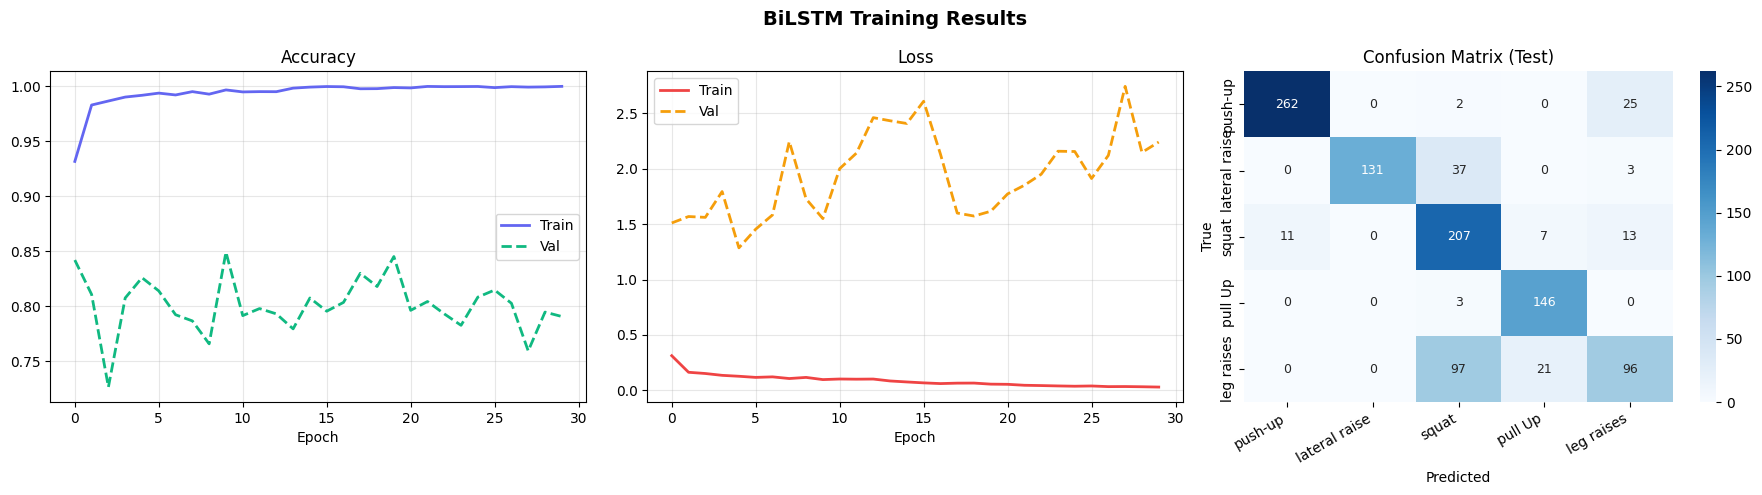

Saved: d:\University_DUT\Semester7\Hoc_may_ung_dung\Project_CK\ExercisePoseAssessment\models\lstm\training_results.png


In [9]:
# ==== CELL 9: Visualize Training + Confusion Matrix ====
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('BiLSTM Training Results', fontsize=14, fontweight='bold')

# Accuracy
ax = axes[0]
ax.plot(history.history['accuracy'],     label='Train', color='#6366f1', linewidth=2)
ax.plot(history.history['val_accuracy'], label='Val',   color='#10b981', linewidth=2, linestyle='--')
ax.set_title('Accuracy'); ax.set_xlabel('Epoch'); ax.legend(); ax.grid(alpha=0.3)

# Loss
ax = axes[1]
ax.plot(history.history['loss'],     label='Train', color='#ef4444', linewidth=2)
ax.plot(history.history['val_loss'], label='Val',   color='#f59e0b', linewidth=2, linestyle='--')
ax.set_title('Loss'); ax.set_xlabel('Epoch'); ax.legend(); ax.grid(alpha=0.3)

# Confusion Matrix
ax = axes[2]
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=labels, yticklabels=labels, ax=ax,
            annot_kws={'size': 9})
ax.set_title('Confusion Matrix (Test)')
ax.set_xlabel('Predicted'); ax.set_ylabel('True')
plt.xticks(rotation=30, ha='right')

plt.tight_layout()
fig_path = os.path.join(MODEL_DIR, 'training_results.png')
plt.savefig(fig_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved: {fig_path}')

In [10]:
# ==== CELL 10: Lưu kết quả summary ====
summary = {
    'model_name'   : 'BiLSTM',
    'model_path'   : BEST_MODEL_PATH,
    'best_epoch'   : best_epoch,
    'val_accuracy' : round(best_val_acc, 4),
    'test_accuracy': round(float(test_acc), 4),
    'test_loss'    : round(float(test_loss), 4),
    'total_params' : model.count_params(),
    'input_shape'  : list(INPUT_SHAPE),
    'n_classes'    : N_CLASSES,
    'label_map'    : LABEL_MAP
}
summary_path = os.path.join(MODEL_DIR, 'model_summary.json')
with open(summary_path, 'w') as f:
    json.dump(summary, f, indent=2)

print('=== LSTM TRAINING COMPLETE ===')
print(f'Best val accuracy : {best_val_acc*100:.2f}%')
print(f'Test accuracy     : {test_acc*100:.2f}%')
print(f'Model saved       : {BEST_MODEL_PATH}')
print('\n>>> Tiếp theo: chạy 04_train_transformer.ipynb <<<')

=== LSTM TRAINING COMPLETE ===
Best val accuracy : 84.92%
Test accuracy     : 79.36%
Model saved       : d:\University_DUT\Semester7\Hoc_may_ung_dung\Project_CK\ExercisePoseAssessment\models\lstm\best_model.h5

>>> Tiếp theo: chạy 04_train_transformer.ipynb <<<
